## Dependencies

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
from IPython.display import display
from pdf2image import convert_from_path

In [3]:
import sys
sys.path.append('../libs')

%load_ext autoreload
%autoreload 2

import ios

## Setup

In [4]:
VERSION = 3
RANDOM_SEED = 12345

VAR_X = ['mean', 'median', 'mode']
DIR = f'../../results/v{VERSION}/gender/predictions/comparison/rs{RANDOM_SEED}/regression/_<VAR_X>/*'
METRIC = 'test_rmse'

## Data

In [5]:
df_results_mean = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mean'))
df_results_median = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'median'))
df_results_mode = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mode'))
df_results = pd.concat([df_results_mean, df_results_median, df_results_mode], ignore_index=True)
df_results.shape

(1147, 18)

In [6]:
cols = ['y','features_id','features','train_eval','test_r2','test_rmse']
df_results[cols].sort_values(METRIC, ascending=True)

,y,features_id,features,train_eval,test_r2,test_rmse
409,median,188,"['ngender_n', 'mean_ngender_rn', 'mean_ngender...",0.029442,0.522669,0.064370
689,median,76,"['ngender_n', 'gender_nw', 'mean_ngender_rn']",0.048729,0.591388,0.112558
354,mean,13,"['ngender_r', 'mean_ngender_rn']",0.069994,0.784022,0.121076
447,median,352,"['ngender_r', 'gender_nw', 'mean_ngender_rn', ...",0.032178,0.288773,0.121726
186,mean,135,"['ngender_r', 'ngender_n', 'mean_ngender_nw', ...",0.101194,0.774856,0.124415
...,...,...,...,...,...,...
423,median,214,"['gender_w', 'gender_nw', 'mean_ngender_rw', '...",0.118697,0.194026,0.273251
1090,mode,2,['gender_n'],0.268230,0.214059,0.286820
1079,mode,24,"['gender_n', 'gender_nw']",0.239894,0.192590,0.290711
780,mode,4,['gender_nw'],0.269654,0.175728,0.293730


In [7]:
best_id = df_results[METRIC].idxmin()
best_id

409

In [8]:
df_results.loc[[best_id], ['y', 'features', 'train_eval','test_rmse','test_r2']]

,y,features,train_eval,test_rmse,test_r2
409,median,"['ngender_n', 'mean_ngender_rn', 'mean_ngender...",0.029442,0.06437,0.522669


In [9]:
df_results.loc[best_id].features

# "['mean_ngender_rw', 'median_ngender_rw', 'mode_ngender_rw']"
# "['ngender_r', 'gender_w_female', 'gender_w_male', 'mean_ngender_rw']"

df_results.loc[best_id].features

"['ngender_n', 'mean_ngender_rn', 'mean_ngender_rw', 'mean_ngender_rnw']"

In [10]:
df_results.loc[best_id]

y                                                            median
features_id                                                     188
features          ['ngender_n', 'mean_ngender_rn', 'mean_ngender...
nfeatures                                                         4
cat_features                                                     []
best_params       {'depth': 2, 'learning_rate': 0.1, 'l2_leaf_re...
best_score        {'learn': {'RMSE': 0.02944172314024984}, 'vali...
best_iteration                                                   47
test_size                                                       0.2
random_state                                                  12345
loss_function                                                  RMSE
eval_metric                                                    RMSE
train_eval                                                 0.029442
test_r2                                                    0.522669
test_rmse                                       

In [11]:
metric = df_results.loc[best_id].y
f_name = DIR.replace('<VAR_X>',metric).replace('/*', "")
f_name = f"{f_name}/{df_results.loc[best_id].y}_{df_results.loc[best_id].features_id}"
f_name

'../../results/v3/gender/predictions/comparison/rs12345/regression/_median/median_188'

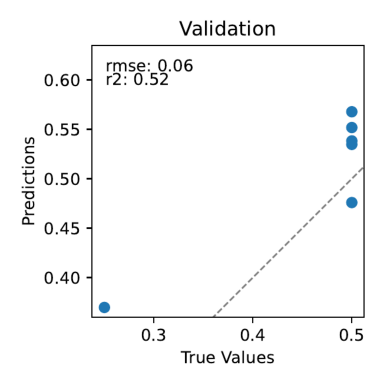

In [12]:
# predictions
fn = f"{f_name}_predictions_val.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



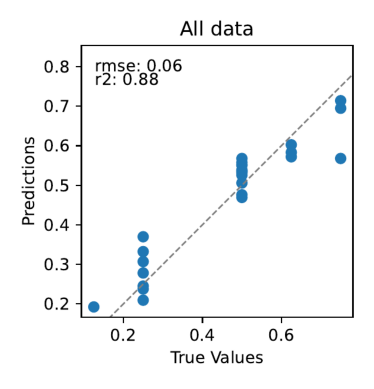

In [13]:
# predictions
fn = f"{f_name}_predictions_all.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



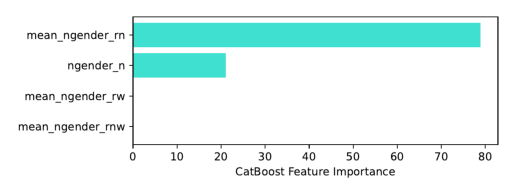

In [14]:
# predictions
fn = f"{f_name}_feature_importance.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



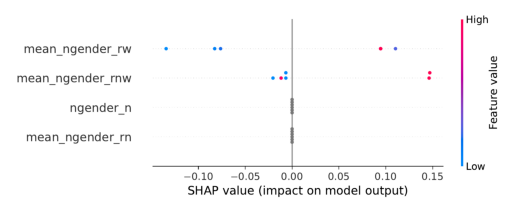

In [15]:
# predictions
fn = f"{f_name}_shap.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()

